# Task 2: Real Estate Housing Price Prediction (OLS, Ridge & Lasso)

**Goal:** Predict median house values for California districts and compare **Ordinary Least Squares (OLS)**, **Ridge (L2)** and **Lasso (L1)** regression using RMSE, MAE and R².

**Pipeline steps**
1. Load the California Housing data with Pandas and inspect it (missing values, target distribution)
2. Exploratory analysis: target distribution, geography, correlation heatmap
3. Feature engineering: ratio and interaction features
4. Multicollinearity check with Variance Inflation Factors (VIF)
5. Preprocessing pipeline: median imputation, standardization, one-hot encoding
6. Fit OLS, Ridge and Lasso; tune `alpha` with `GridSearchCV`
7. Compare RMSE, MAE and R² on a held-out test set
8. Residual analysis: predicted vs. actual, residual distributions, coefficients

**Tools:** Python, Pandas, Scikit-Learn (LinearRegression, Ridge, Lasso, GridSearchCV), Seaborn, Matplotlib

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning

# Lasso with very small alpha values (which are never selected) can emit harmless convergence warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

RESULTS = Path("../results")
RESULTS.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    """Save the current figure into the results folder."""
    plt.savefig(RESULTS / name, dpi=150, bbox_inches="tight")

## 1. Load the dataset with Pandas

The data is read from `data/housing.csv` (the California Housing dataset with 20,640 districts).

In [ ]:
DATA_PATH = Path("data/housing.csv")

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())
display(df.describe().round(2).T)

print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nocean_proximity categories:")
print(df["ocean_proximity"].value_counts())

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,20640.0,2635.76,2181.62,2.00,1447.75,2127.00,3148.00,39320.00
total_bedrooms,20433.0,537.87,421.39,1.00,296.00,435.00,647.00,6445.00
population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
households,20640.0,499.54,382.33,1.00,280.00,409.00,605.00,6082.00
median_income,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,20640.0,206855.82,115395.62,14999.00,119600.00,179700.00,264725.00,500001.00



Missing values per column:
total_bedrooms    207
dtype: int64

ocean_proximity categories:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


**Observations**
- `total_bedrooms` has missing values, so they must be imputed.
- `ocean_proximity` is categorical and must be encoded.
- The target `median_house_value` is **capped** at about 500,000, which will matter for the residual analysis.

## 2. Exploratory analysis

Districts at the 500,000 price cap: 992 (4.8%)


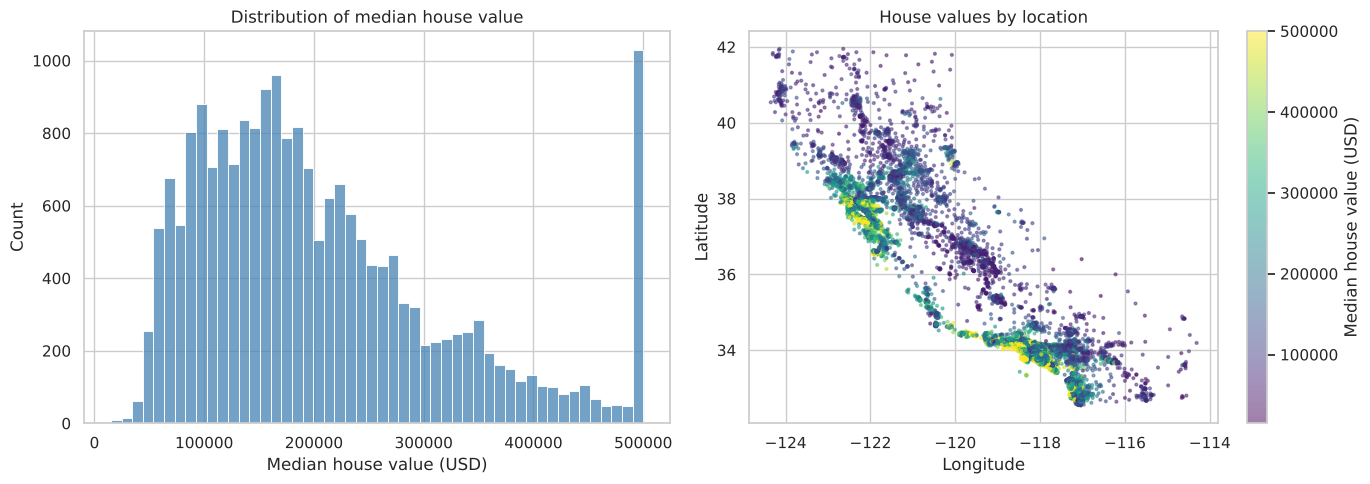

In [3]:
capped = int((df["median_house_value"] >= 500000).sum())
print(f"Districts at the 500,000 price cap: {capped} ({capped / len(df):.1%})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["median_house_value"], bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of median house value")
axes[0].set_xlabel("Median house value (USD)")

sc = axes[1].scatter(df["longitude"], df["latitude"], c=df["median_house_value"],
                     cmap="viridis", s=4, alpha=0.5)
plt.colorbar(sc, ax=axes[1], label="Median house value (USD)")
axes[1].set_title("House values by location")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
save_fig("eda_target_and_geography.png")
plt.show()

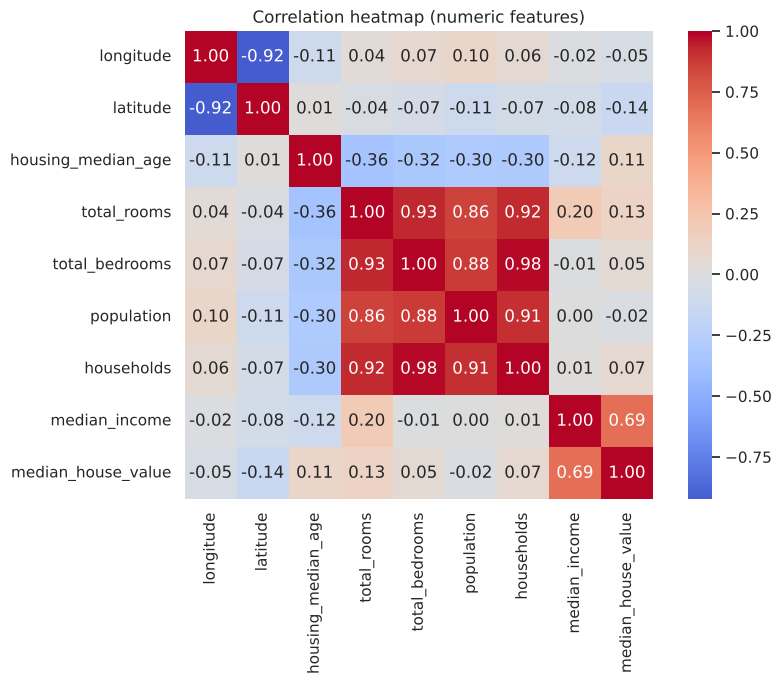

Correlation with the target:
median_income         0.688
total_rooms           0.134
housing_median_age    0.106
households            0.066
total_bedrooms        0.050
population           -0.025
longitude            -0.046
latitude             -0.144
Name: median_house_value, dtype: float64


In [4]:
corr = df.select_dtypes("number").corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap (numeric features)")
plt.tight_layout()
save_fig("correlation_heatmap.png")
plt.show()

print("Correlation with the target:")
print(corr["median_house_value"].drop("median_house_value").sort_values(ascending=False).round(3))

**Observations:** `median_income` is by far the strongest predictor of house value. `total_rooms`, `total_bedrooms`, `population` and `households` are almost perfectly correlated with each other, which is a clear sign of **multicollinearity**. `latitude` and `longitude` are also strongly (negatively) correlated.

## 3. Train/test split and feature engineering

The data is split **before** any statistics are computed (80/20), so the test set stays untouched. Means used for centering are taken from the training set only, which avoids data leakage.

New features:
- `rooms_per_household`, `bedrooms_per_room`, `population_per_household`: ratios that describe a district better than raw counts
- `income_x_age`, `income_x_rooms`: **interaction features** (products of *centered* variables, which keeps them from being highly correlated with their components)

In [5]:
X = df.drop(columns="median_house_value")
y = df["median_house_value"]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train_raw)} rows | Test: {len(X_test_raw)} rows")

# statistics from the training set only
income_mean = X_train_raw["median_income"].mean()
age_mean = X_train_raw["housing_median_age"].mean()
rph_mean = (X_train_raw["total_rooms"] / X_train_raw["households"]).mean()


def add_features(data):
    data = data.copy()
    data["rooms_per_household"] = data["total_rooms"] / data["households"]
    data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"]
    data["population_per_household"] = data["population"] / data["households"]
    data["income_x_age"] = (data["median_income"] - income_mean) * (data["housing_median_age"] - age_mean)
    data["income_x_rooms"] = (data["median_income"] - income_mean) * (data["rooms_per_household"] - rph_mean)
    return data


X_train_fe = add_features(X_train_raw)
X_test_fe = add_features(X_test_raw)

new_cols = ["rooms_per_household", "bedrooms_per_room", "population_per_household",
            "income_x_age", "income_x_rooms"]
display(X_train_fe[new_cols].describe().round(3).T)
print("Missing values in training features:")
print(X_train_fe.isna().sum()[X_train_fe.isna().sum() > 0])

Train: 16512 rows | Test: 4128 rows


,count,mean,std,min,25%,50%,75%,max
rooms_per_household,16512.0,5.435,2.387,0.889,4.452,5.236,6.061,141.909
bedrooms_per_room,16512.0,0.213,0.058,0.100,0.175,0.203,0.240,1.000
population_per_household,16512.0,3.097,11.579,0.692,2.429,2.817,3.280,1243.333
income_x_age,16512.0,-2.921,25.545,-295.867,-11.784,-0.925,6.469,260.101
income_x_rooms,16512.0,1.528,5.243,-273.733,0.005,0.583,2.028,186.660


Missing values in training features:
Series([], dtype: int64)


## 4. Multicollinearity: Variance Inflation Factor (VIF)

The VIF of a feature is `1 / (1 - R²)`, where R² comes from regressing that feature on all the other features. A VIF above **10** signals serious multicollinearity, and above **5** is already worth a look.

In [6]:
def compute_vif(frame):
    """VIF for every numeric column (each column regressed on all the others)."""
    values = {}
    for col in frame.columns:
        others = frame.drop(columns=col)
        r2 = LinearRegression().fit(others, frame[col]).score(others, frame[col])
        values[col] = np.inf if r2 >= 1 else 1.0 / (1.0 - r2)
    return pd.Series(values).sort_values(ascending=False)


numeric_cols = X_train_fe.select_dtypes("number").columns.tolist()
numeric_filled = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_train_fe[numeric_cols]),
    columns=numeric_cols,
)

vif_before = compute_vif(numeric_filled)
display(vif_before.round(2).to_frame("VIF (all features)"))

,VIF (all features)
total_bedrooms,50.99
households,47.07
total_rooms,19.61
latitude,9.61
longitude,9.24
population,6.87
median_income,3.02
bedrooms_per_room,2.92
rooms_per_household,2.11
income_x_rooms,1.61


**Handling the multicollinearity:** the raw count columns (`total_rooms`, `total_bedrooms`, `population`, `households`) measure the same thing, the size of a district. The per-household ratios created above carry the useful information without that redundancy, so the four raw counts are dropped.

,VIF (after dropping raw counts)
latitude,9.42
longitude,9.08
median_income,2.81
bedrooms_per_room,1.98
rooms_per_household,1.57
income_x_rooms,1.56
housing_median_age,1.12
income_x_age,1.03
population_per_household,1.00


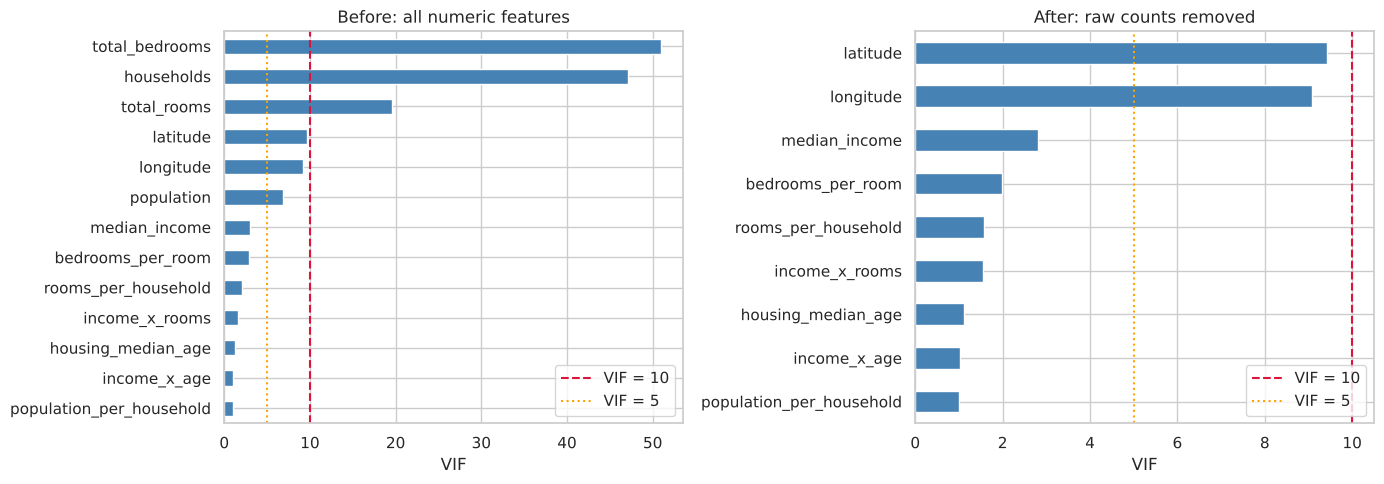

In [7]:
drop_cols = ["total_rooms", "total_bedrooms", "population", "households"]
selected_numeric = [c for c in numeric_cols if c not in drop_cols]

vif_after = compute_vif(numeric_filled[selected_numeric])
display(vif_after.round(2).to_frame("VIF (after dropping raw counts)"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=False)
for ax, data, title in zip(axes, [vif_before, vif_after],
                           ["Before: all numeric features", "After: raw counts removed"]):
    data.sort_values().plot(kind="barh", ax=ax, color="steelblue")
    ax.axvline(10, color="crimson", linestyle="--", label="VIF = 10")
    ax.axvline(5, color="orange", linestyle=":", label="VIF = 5")
    ax.set_title(title)
    ax.set_xlabel("VIF")
    ax.legend()
plt.tight_layout()
save_fig("vif_before_after.png")
plt.show()

Some correlation remains (mainly between `latitude` and `longitude`, which together encode location). That is acceptable here, because Ridge and Lasso are regularized methods built to stay stable when features are correlated. Comparing them with plain OLS shows exactly that benefit.

## 5. Preprocessing pipeline

All preprocessing lives inside a scikit-learn `Pipeline`, so it is fitted on training data only (also inside each cross-validation fold):
- numeric features: **median imputation**, then **standardization** (`StandardScaler`)
- categorical feature `ocean_proximity`: **one-hot encoding**

In [8]:
num_features = selected_numeric
cat_features = ["ocean_proximity"]
feature_cols = num_features + cat_features

X_train = X_train_fe[feature_cols]
X_test = X_test_fe[feature_cols]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

print("Numeric features:", num_features)
print("Categorical features:", cat_features)

Numeric features: ['longitude', 'latitude', 'housing_median_age', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_age', 'income_x_rooms']
Categorical features: ['ocean_proximity']


## 6. Train the models

- **OLS** has no hyperparameter.
- **Ridge (L2)** and **Lasso (L1)** are tuned with `GridSearchCV` over many `alpha` values (5-fold cross-validation, scored by RMSE).

The target is standardized inside a `TransformedTargetRegressor`. This keeps the regularization strength `alpha` on a sensible scale and helps Lasso converge, while all predictions and metrics are still reported in **US dollars**.

In [9]:
def build_candidates():
    return {
        "OLS": (LinearRegression(), None),
        "Ridge (L2)": (Ridge(), {"regressor__model__alpha": np.logspace(-3, 4, 29)}),
        "Lasso (L1)": (Lasso(max_iter=10000), {"regressor__model__alpha": np.logspace(-6, -1, 11)}),
    }


def fit_all(preprocessor, verbose=True):
    """Fit OLS, Ridge and Lasso on the training set; tune alpha with GridSearchCV."""
    fitted, searches, cv_rmse = {}, {}, {}
    for name, (estimator, grid) in build_candidates().items():
        pipe = Pipeline([("prep", preprocessor), ("model", estimator)])
        model = TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())
        if grid is None:
            scores = cross_val_score(model, X_train, y_train, cv=5,
                                     scoring="neg_root_mean_squared_error")
            cv_rmse[name] = -scores.mean()
            fitted[name] = model.fit(X_train, y_train)
        else:
            search = GridSearchCV(model, grid, cv=5,
                                  scoring="neg_root_mean_squared_error")
            search.fit(X_train, y_train)
            searches[name] = search
            fitted[name] = search.best_estimator_
            cv_rmse[name] = -search.best_score_
            if verbose:
                print(f"{name}: best alpha = {search.best_params_['regressor__model__alpha']:.4g}")
    return fitted, searches, cv_rmse


fitted, searches, cv_rmse = fit_all(preprocess)

print("\n5-fold CV RMSE on the training set (USD):")
print(pd.Series(cv_rmse).round(1))

Ridge (L2): best alpha = 0.5623


Lasso (L1): best alpha = 1e-05

5-fold CV RMSE on the training set (USD):
OLS           70272.9
Ridge (L2)    70272.1
Lasso (L1)    70272.9
dtype: float64


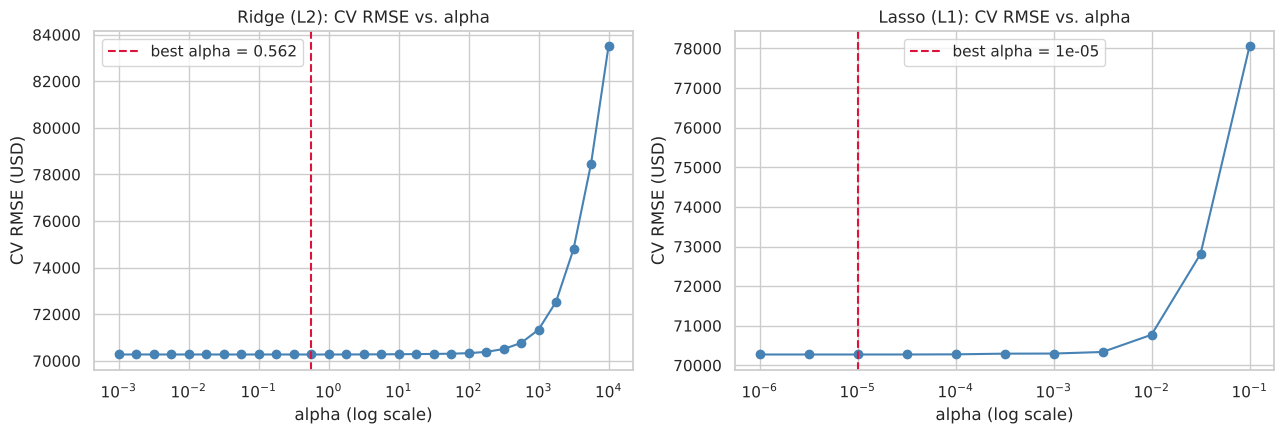

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name in zip(axes, ["Ridge (L2)", "Lasso (L1)"]):
    res = searches[name].cv_results_
    alphas = [p["regressor__model__alpha"] for p in res["params"]]
    rmse = -res["mean_test_score"]
    ax.semilogx(alphas, rmse, marker="o", color="steelblue")
    best = searches[name].best_params_["regressor__model__alpha"]
    ax.axvline(best, color="crimson", linestyle="--", label=f"best alpha = {best:.3g}")
    ax.set_title(f"{name}: CV RMSE vs. alpha")
    ax.set_xlabel("alpha (log scale)")
    ax.set_ylabel("CV RMSE (USD)")
    ax.legend()
plt.tight_layout()
save_fig("alpha_search.png")
plt.show()

## 7. Benchmark: RMSE, MAE and R²

All metrics are computed on the **held-out test set**. Training metrics are shown as well to check for overfitting.

In [11]:
def evaluate(model, features, target):
    pred = model.predict(features)
    return {
        "RMSE": np.sqrt(mean_squared_error(target, pred)),
        "MAE": mean_absolute_error(target, pred),
        "R²": r2_score(target, pred),
    }


test_results = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in fitted.items()}).T
train_results = pd.DataFrame({n: evaluate(m, X_train, y_train) for n, m in fitted.items()}).T

print("=== Test set ===")
display(test_results.round(4))
print("=== Training set ===")
display(train_results.round(4))

=== Test set ===


,RMSE,MAE,R²
OLS,71557.8058,51254.6673,0.6092
Ridge (L2),71562.0281,51258.7010,0.6092
Lasso (L1),71559.1612,51255.9607,0.6092


=== Training set ===


,RMSE,MAE,R²
OLS,70193.2119,50951.8059,0.6314
Ridge (L2),70193.5910,50952.5615,0.6314
Lasso (L1),70193.2516,50952.0012,0.6314


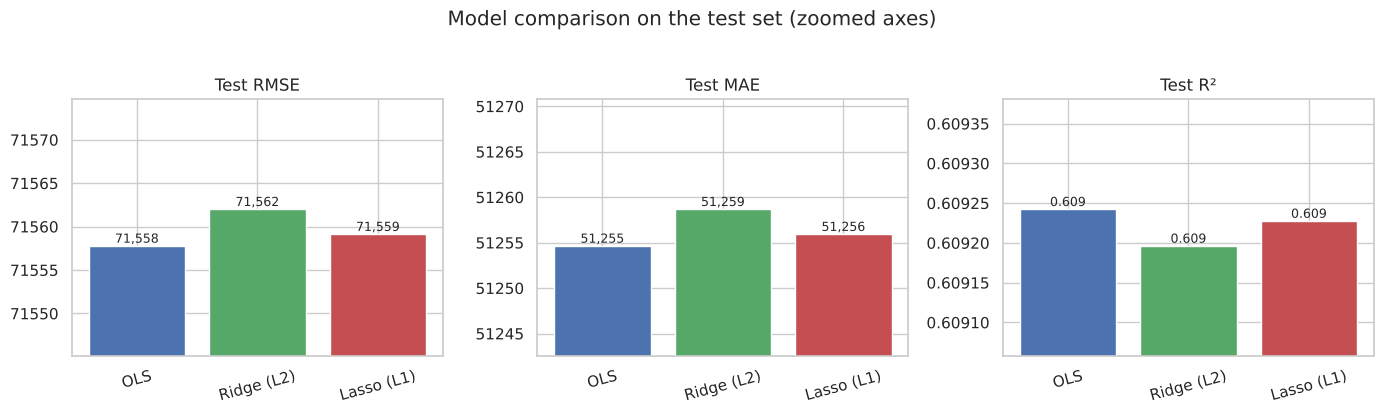

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
palette = ["#4c72b0", "#55a868", "#c44e52"]
for ax, metric in zip(axes, ["RMSE", "MAE", "R²"]):
    values = test_results[metric]
    ax.bar(values.index, values.values, color=palette)
    ax.set_title(f"Test {metric}")
    ax.tick_params(axis="x", rotation=15)
    spread = values.max() - values.min()
    ax.set_ylim(values.min() - 3 * spread - 1e-9, values.max() + 3 * spread + 1e-9)
    for i, v in enumerate(values.values):
        ax.text(i, v, f"{v:,.3f}" if metric == "R²" else f"{v:,.0f}",
                ha="center", va="bottom", fontsize=9)
plt.suptitle("Model comparison on the test set (zoomed axes)", y=1.03)
plt.tight_layout()
save_fig("model_comparison.png")
plt.show()

## 8. Residual error analysis

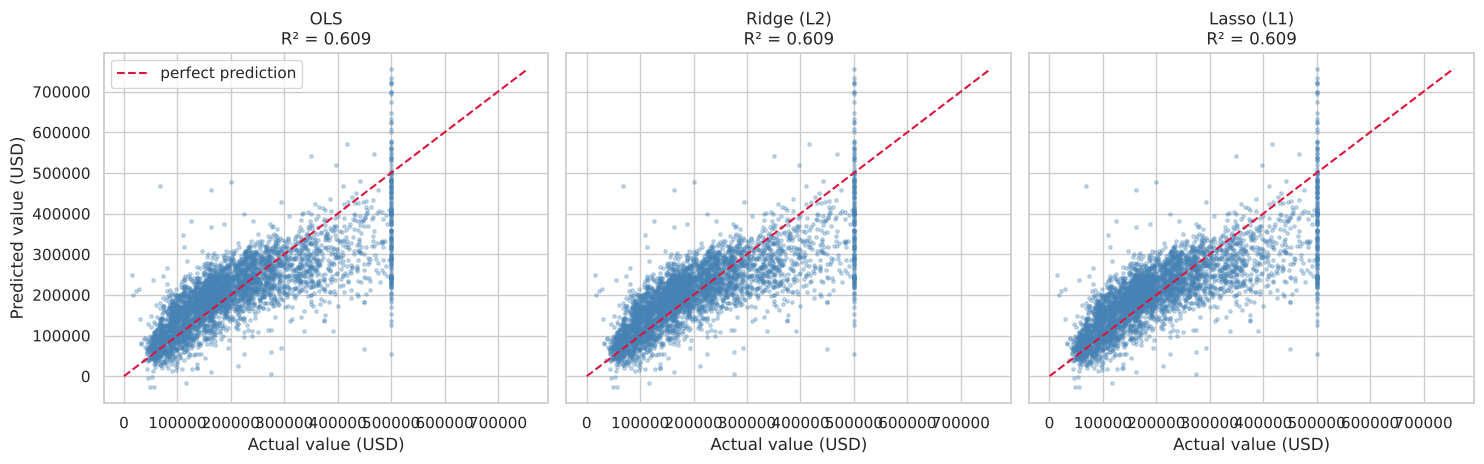

In [13]:
predictions = {n: m.predict(X_test) for n, m in fitted.items()}
residuals = {n: y_test.values - p for n, p in predictions.items()}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)
lims = [0, max(y_test.max(), max(p.max() for p in predictions.values()))]
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, s=6, alpha=0.3, color="steelblue")
    ax.plot(lims, lims, color="crimson", linestyle="--", label="perfect prediction")
    ax.set_title(f"{name}\nR² = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Actual value (USD)")
axes[0].set_ylabel("Predicted value (USD)")
axes[0].legend()
plt.tight_layout()
save_fig("predicted_vs_actual.png")
plt.show()

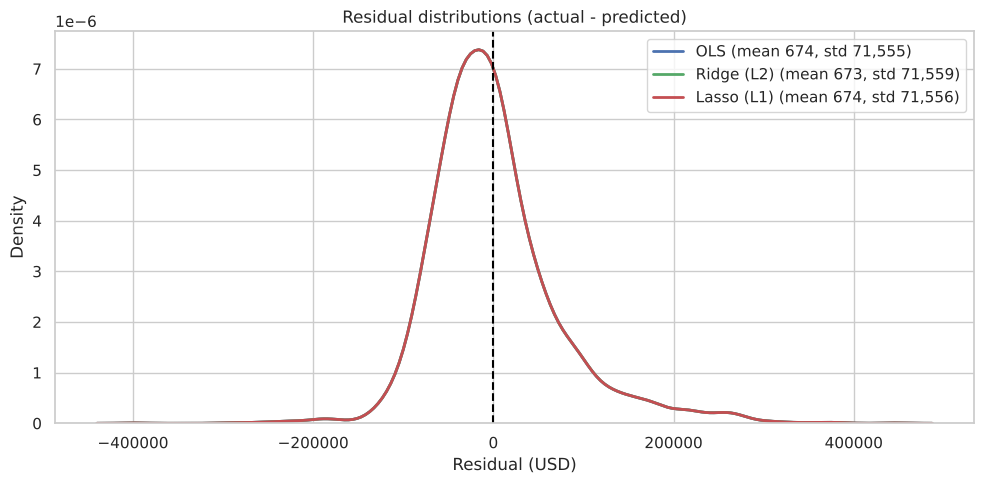

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
for (name, res), color in zip(residuals.items(), palette):
    sns.kdeplot(res, ax=ax, label=f"{name} (mean {res.mean():,.0f}, std {res.std():,.0f})",
                color=color, linewidth=2)
ax.axvline(0, color="black", linestyle="--")
ax.set_title("Residual distributions (actual - predicted)")
ax.set_xlabel("Residual (USD)")
ax.legend()
plt.tight_layout()
save_fig("residual_distributions.png")
plt.show()

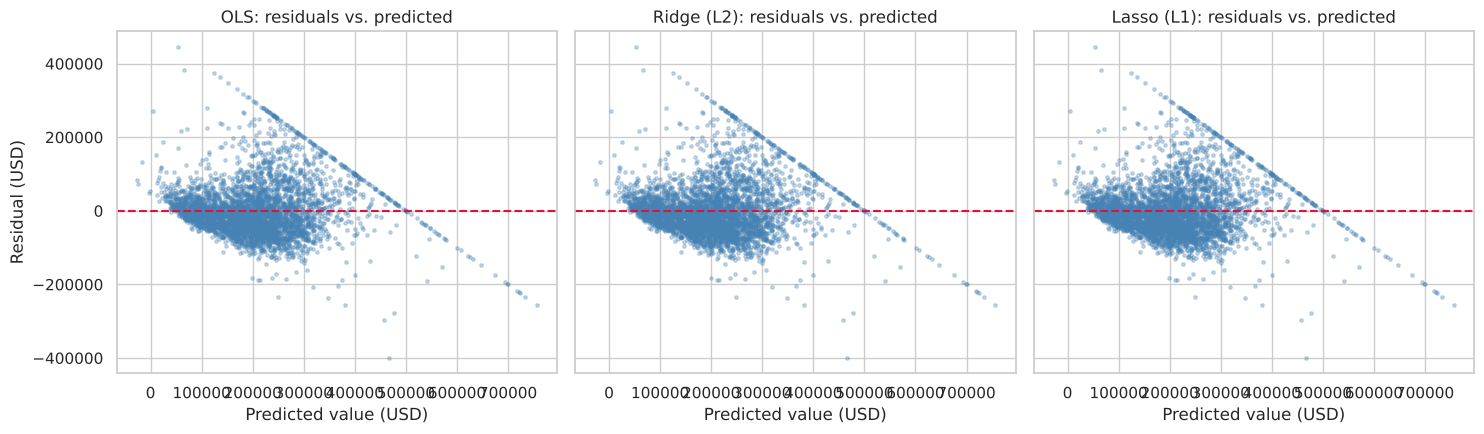

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(pred, residuals[name], s=6, alpha=0.3, color="steelblue")
    ax.axhline(0, color="crimson", linestyle="--")
    ax.set_title(f"{name}: residuals vs. predicted")
    ax.set_xlabel("Predicted value (USD)")
axes[0].set_ylabel("Residual (USD)")
plt.tight_layout()
save_fig("residuals_vs_predicted.png")
plt.show()

### Coefficients: what do Ridge and Lasso change?

,OLS,Ridge (L2),Lasso (L1)
longitude,-53339.1,-53315.0,-53321.5
latitude,-52325.4,-52305.7,-52308.4
housing_median_age,11027.5,11030.6,11027.8
median_income,86163.3,86157.8,86160.2
rooms_per_household,5768.9,5770.9,5767.5
bedrooms_per_room,21050.5,21050.3,21048.0
population_per_household,-4349.8,-4349.7,-4348.6
income_x_age,4609.1,4608.1,4607.8
income_x_rooms,-6470.4,-6467.9,-6468.3
ocean_proximity_<1H OCEAN,-23612.6,-20652.6,-3070.5


Features set exactly to zero by Lasso: ['ocean_proximity_NEAR BAY']


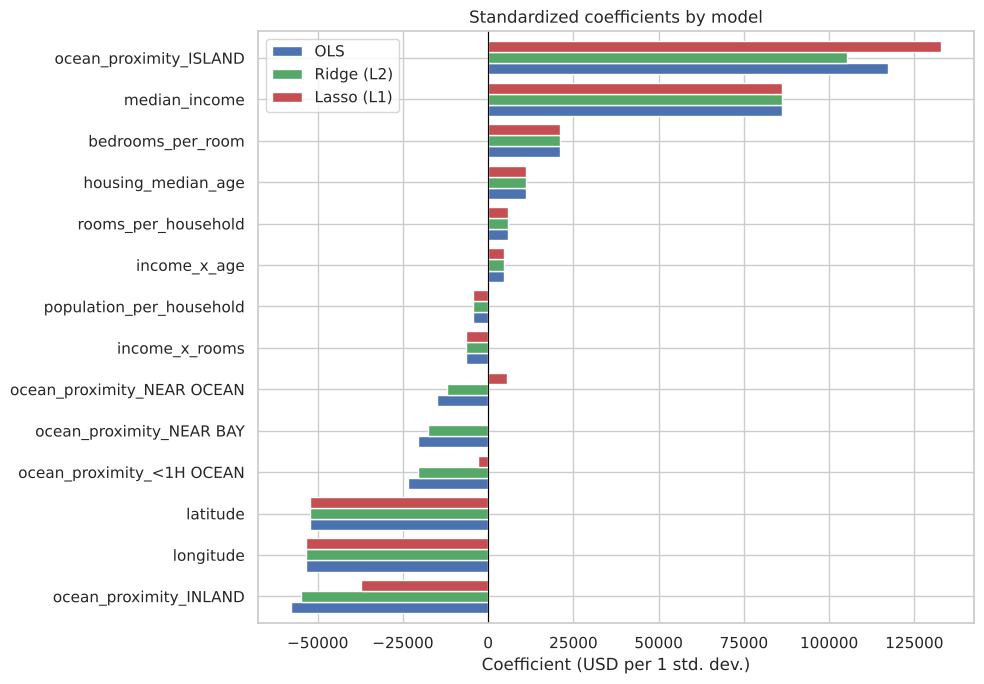

In [16]:
def get_coefficients(models):
    """Coefficients in USD per 1 standard deviation of each (scaled) feature."""
    first = next(iter(models.values()))
    names = [n.split("__", 1)[1]
             for n in first.regressor_.named_steps["prep"].get_feature_names_out()]
    table = {}
    for name, model in models.items():
        target_std = model.transformer_.scale_[0]
        table[name] = model.regressor_.named_steps["model"].coef_ * target_std
    return pd.DataFrame(table, index=names)


coefs = get_coefficients(fitted)
display(coefs.round(1))

zeroed = coefs.index[coefs["Lasso (L1)"] == 0].tolist()
print("Features set exactly to zero by Lasso:", zeroed if zeroed else "none")

coefs.sort_values("OLS").plot(kind="barh", figsize=(10, 7), width=0.8, color=palette)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Standardized coefficients by model")
plt.xlabel("Coefficient (USD per 1 std. dev.)")
plt.tight_layout()
save_fig("coefficients.png")
plt.show()

## 9. Bonus experiment: all pairwise interaction features

With the cleaned feature set, the three models perform almost identically, because there is little multicollinearity left for regularization to fix. Regularization matters much more when the feature space is **large and redundant**. To show this, the numeric features are expanded with **all pairwise interactions and squares** (`PolynomialFeatures`, degree 2), which creates many correlated columns, and the three models are compared again.

In [17]:
preprocess_poly = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler2", StandardScaler()),
    ]), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

fitted_poly, searches_poly, cv_rmse_poly = fit_all(preprocess_poly)

test_poly = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in fitted_poly.items()}).T
train_poly = pd.DataFrame({n: evaluate(m, X_train, y_train) for n, m in fitted_poly.items()}).T

n_features = len(get_coefficients(fitted_poly))
lasso_coefs = get_coefficients(fitted_poly)["Lasso (L1)"]
print(f"\nFeatures after expansion: {n_features}")
print(f"Features kept by Lasso: {(lasso_coefs != 0).sum()} (set to zero: {(lasso_coefs == 0).sum()})")

print("\n=== Test set (with interaction expansion) ===")
display(test_poly.round(4))
print("=== Training set (with interaction expansion) ===")
display(train_poly.round(4))

comparison = pd.DataFrame({
    "Test RMSE (cleaned features)": test_results["RMSE"],
    "Test RMSE (all interactions)": test_poly["RMSE"],
    "Test R² (cleaned features)": test_results["R²"],
    "Test R² (all interactions)": test_poly["R²"],
}).round(4)
display(comparison)

Ridge (L2): best alpha = 1000


Lasso (L1): best alpha = 0.01

Features after expansion: 59
Features kept by Lasso: 26 (set to zero: 33)

=== Test set (with interaction expansion) ===


,RMSE,MAE,R²
OLS,72838.7253,45891.6210,0.5951
Ridge (L2),69747.6855,49161.5690,0.6288
Lasso (L1),70117.8634,49861.7777,0.6248


=== Training set (with interaction expansion) ===


,RMSE,MAE,R²
OLS,63303.4323,44408.8777,0.7002
Ridge (L2),67767.6909,48968.1133,0.6565
Lasso (L1),68576.1708,49612.9639,0.6482


,Test RMSE (cleaned features),Test RMSE (all interactions),Test R² (cleaned features),Test R² (all interactions)
OLS,71557.8058,72838.7253,0.6092,0.5951
Ridge (L2),71562.0281,69747.6855,0.6092,0.6288
Lasso (L1),71559.1612,70117.8634,0.6092,0.6248


## 10. Conclusion

### Main experiment (cleaned features)
- **OLS, Ridge and Lasso perform essentially the same** on the test set: RMSE ≈ \$71.6k, MAE ≈ \$51.3k, R² ≈ 0.609. The training R² (0.631) is close to the test R² (0.609), so there is no strong overfitting.
- The reason is that, after the multicollinearity cleanup (highest remaining VIF ≈ 9, between latitude and longitude) and with 16,500 training rows, there is little left for regularization to fix. Cross-validation therefore picked very small `alpha` values (Ridge ≈ 0.56, Lasso ≈ 1e-5), and Lasso set only one coefficient to zero (`ocean_proximity_NEAR BAY`).
- `median_income` is by far the most influential feature, followed by location (`latitude`, `longitude`) and the `ocean_proximity` category.

### Residual analysis
- Residuals are centered close to zero (mean ≈ \$670) but **right-skewed**, with a long tail of districts that are much more expensive than predicted.
- The **diagonal line of points** in the residual plot and the **vertical line** in the predicted-vs-actual plot come from the **price cap**: 992 districts (4.8%) are recorded at exactly \$500,001, so the true value is censored and errors there are artificially large.
- The spread of the residuals is not constant and the cloud is not centered at zero for all predicted values, so the linear assumption is only an approximation of the real price structure (especially for location).

### Bonus experiment (59 interaction features)
- With all pairwise interactions and squares, **OLS overfits**: training R² rises to 0.700 while test R² drops to 0.595, which is worse than OLS on the 9 cleaned features.
- **Ridge (test R² 0.629, RMSE ≈ \$69.7k)** and **Lasso (test R² 0.625, RMSE ≈ \$70.1k)** generalize better, and Lasso does it with only **26 of the 59 features**. This is where regularization pays off: when the feature space is large and redundant.

### Limitations and next steps
- A single train/test split was used; repeated cross-validation would give more robust estimates.
- The capped target could be handled explicitly (for example by removing capped districts or using a censored-data model).
- Linear models reach R² ≈ 0.63 at best here; tree-based models (Random Forest, Gradient Boosting) would likely capture the non-linear effect of location much better.